This colab notebook is reponsible for running the whole training and evaluation pipeline. This notebook trains the Multimodal Graph Neural Network on a portion of the CLEVR_v1.0 dataset. The code here is adapted from the following GitHub repository: https://github.com/raeidsaqur/mgn

First, let's mount the the google drive so that it has access to the dataset and the codebase.

In [ ]:
from google.colab import drive
drive.mount("/content/gdrive")

Mounted at /content/gdrive


Next, lets install all the dependencies needed to run the pipeline. We use PyTorch 1.10 and implement Graph Neural Networks using PyG!

In [ ]:
%cd "/content/gdrive/My Drive/MGN/MultimodalGNN-VQA/mgn/tools"
!pip install rsmlkit torch_geometric -f https://data.pyg.org/whl/torch-1.10.0+cu113.html torch-sparse -f https://data.pyg.org/whl/torch-1.10.0+cu113.html torch-scatter -f https://data.pyg.org/whl/torch-1.10.0+cu113.html
!git clone https://github.com/raeidsaqur/clevr-parser
%cd clevr-parser
!pip install -e .
!apt install libgraphviz-dev
!pip install spacy-transformers==0.5.3 albumentations==0.2.3 kapre==0.2.0 datascience==0.17.0 timm==0.4.12 wandb
!pip install -r requirements.txt
%cd ..

/content/gdrive/My Drive/MGN/MultimodalGNN-VQA/mgn/tools
Looking in links: https://data.pyg.org/whl/torch-1.10.0+cu113.html, https://data.pyg.org/whl/torch-1.10.0+cu113.html, https://data.pyg.org/whl/torch-1.10.0+cu113.html
fatal: destination path 'clevr-parser' already exists and is not an empty directory.
/content/gdrive/My Drive/MGN/MultimodalGNN-VQA/mgn/tools/clevr-parser
Obtaining file:///content/gdrive/My%20Drive/MGN/MultimodalGNN-VQA/mgn/tools/clevr-parser
  Attempting uninstall: clevr-parser
    Found existing installation: clevr-parser 0.0.7
    Can't uninstall 'clevr-parser'. No files were found to uninstall.
  Running setup.py develop for clevr-parser
Reading package lists... Done
Building dependency tree       
Reading state information... Done
libgraphviz-dev is already the newest version (2.40.1-2).
0 upgraded, 0 newly installed, 0 to remove and 37 not upgraded.
/content/gdrive/My Drive/MGN/MultimodalGNN-VQA/mgn/tools


Here we preprocess the CLEVR dataset to make training faster. Preprocessing consists of tokenizing questions and answers, embedding tokenized text, embedding and extracting graphs from images, and finally saving everything in an .h5 file as a dataset.

In [ ]:
#! /usr/bin/env python3
# -*- coding: utf-8 -*-

# preprocess clevr questions
# code adopted from https://github.com/facebookresearch/clevr-iep/blob/master/scripts/preprocess_questions.py

import os, sys
import os.path as osp
import argparse
import json
from typing import *

import random

random.seed(42)

nb_dir = os.path.split(os.getcwd())[0]
if nb_dir not in sys.path:
    sys.path.insert(0, nb_dir)
sys.path.insert(0, ".")

import utils.preprocess as preprocess_utils
import utils.programs as program_utils
import utils.utils as utils
from utils.mgn_preproc_utils import get_questions_and_parsed_scenes, \
    save_graph_pairdata, save_h5
from datasets import ClevrData

import clevr_parser
import clevr_parser.utils as parser_utils

from rsmlkit.logging import get_logger, set_default_level
logger = get_logger()


def program_to_str(program, mode):
  """ Convert string representing the type question execution to a program object"""
  if mode == 'chain':
      if not program_utils.is_chain(program):
          return None
      return program_utils.list_to_str(program)
  elif mode == 'prefix':
      program_prefix = program_utils.list_to_prefix(program)
      return program_utils.list_to_str(program_prefix)
  elif mode == 'postfix':
      program_postfix = program_utils.list_to_postfix(program)
      return program_utils.list_to_str(program_postfix)
  return None


def _process_vocab(input_vocab_json, expand_vocab, unk_threshold, mode,
                   questions, output_vocab_json) -> Dict:
    """If input_vocab_json is provided, then use (or expand) it, o.w. build vocab from train files"""
    # Either create the vocab or load it from disk
    if input_vocab_json == '' or expand_vocab == 1:
        logger.info('Building vocab')
        if 'answer' in questions[0]:
            answer_token_to_idx = preprocess_utils.build_vocab(
                (q['answer'] for q in questions)
            )
        question_token_to_idx = preprocess_utils.build_vocab(
            (q['question'] for q in questions),
            min_token_count=unk_threshold,
            punct_to_keep=[';', ','], punct_to_remove=['?', '.']
        )
        all_program_strs = []
        for q in questions:
            if 'program' not in q: continue
            program_str = program_to_str(q['program'], mode)
            if program_str is not None:
                all_program_strs.append(program_str)
        program_token_to_idx = preprocess_utils.build_vocab(all_program_strs)
        vocab = {
            'question_token_to_idx': question_token_to_idx,
            'program_token_to_idx': program_token_to_idx,
            'answer_token_to_idx': answer_token_to_idx,
        }

    if input_vocab_json != '':
        logger.info('Loading vocab')
        if expand_vocab == 1:
            new_vocab = vocab
        with open(input_vocab_json) as f:
            vocab = json.load(f)
        if expand_vocab == 1:
            num_new_words = 0
            for word in new_vocab['question_token_to_idx']:
                if word not in vocab['question_token_to_idx']:
                    logger.info('Found new word %s' % word)
                    idx = len(vocab['question_token_to_idx'])
                    vocab['question_token_to_idx'][word] = idx
                    num_new_words += 1
            logger.info('Found %d new words' % num_new_words)

    if output_vocab_json != '':
        utils.mkdirs(os.path.dirname(output_vocab_json))
        with open(output_vocab_json, 'w') as f:
            json.dump(vocab, f)

    return vocab

def _get_out_dir_and_file_prefix(output_h5_file):
    """Extract the directory of a file and its name from complete path"""
    output_h5_file = output_h5_file
    out_dir = osp.dirname(output_h5_file)
    out_f_prefix = osp.basename(output_h5_file).split('.')[0]  # clevr_train_questions

    return out_dir, out_f_prefix

def preprocess_clevr_mgn(input_questions_json, input_parsed_img_scenes_json, output_h5_file, mode='prefix', input_vocab_json='',
         expand_vocab=0, unk_threshold=1, encode_unk=0, output_vocab_json='',
         is_debug=False, max_sample=10, checkpoint_every=100, is_directed_graph=True,
         parser_lm='en_core_web_sm', model=''):
    """
    Save nx.graph (Gss, Gts,...) and corresponding torch_geometric.data.PairData
    (via clevr_parse embedder api).
    input_questions_json: raw json mapping questions to answers and image indices.
    input_parsed_img_scenes_json: json mapping images to the parsed scene describing the image contents
    output_h5_file: path to the final .h5 file
    mode: type of questions in the dataset
    input_vocab_json: vocab of the input questions, if available. Must be provided if output_vocab_json is not.
    expand_vocab: if vocab should be expanded by breaking words
    unk_threshold: threshold for labelling a word as unknown.
    encode_unk: whether unknown tokens should be encoded.
    output_vocab_json: path to the final vocab json. Must be provided if input_vocab_json is not.
    is_debug: whether to run preprocessing in the debug mode
    max_sample: maximum number of questions that should be processed from raw files.
    checkpoint_every: frequency with which to create checkpoints of the processed questions
    is_directed_graph: whether the graph created from images is directed or not
    parser_lm: language model to be used for parsing and embedding questions
    """
    if (input_vocab_json == '') and (output_vocab_json == ''):
        logger.info('Must give one of --input_vocab_json or --output_vocab_json')
        return
    graph_parser = clevr_parser.Parser(backend='spacy', model=parser_lm,
                                       has_spatial=True,
                                       has_matching=True).get_backend(identifier='spacy')
    embedder = clevr_parser.Embedder(backend='torch', parser=graph_parser).get_backend(identifier='torch')

    out_dir, out_f_prefix = _get_out_dir_and_file_prefix(output_h5_file)
    checkpoint_dir = f"{out_dir}/checkpoints"
    utils.mkdirs(checkpoint_dir)

    questions, img_scenes = get_questions_and_parsed_scenes(input_questions_json,
                                                            input_parsed_img_scenes_json)
    if is_debug:
        set_default_level(10)
        questions = questions[:128]  # default BSZ is 64 ensuring enought for batch iter
        logger.debug(f"In DEBUG mode, sampling {len(questions)} questions only..")
    # Process Vocab #
    vocab = _process_vocab(input_vocab_json, expand_vocab, unk_threshold, mode, questions, output_vocab_json)

    # Encode all questions and programs
    logger.info('Encoding data')
    questions_encoded, programs_encoded, answers, image_idxs = [], [], [], []
    question_families = []
    orig_idxs = []

    # Graphs and Embeddings #
    data_s_list = []  # List [torch_geometric.data.Data]
    data_t_list = []  # List [torch_geometric.data.Data]
    num_samples = 0  # Counter for keeping track of processed samples
    num_skipped = 0  # Counter for tracking num of samples skipped
    for orig_idx, q in enumerate(questions):
        # First See if Gss, Gts are possible to extract.
        # If not (for e.g., some edges cases like plurality, skip data sample
        img_idx = q['image_index']
        img_fn = q['image_filename']
        if img_idx > 100:
            continue
        logger.debug(f"\tProcessing Image - {img_idx}: {img_fn} ...")
        # q_idx = q['question_index']
        # q_fam_idx = q['question_family_index']
        ## 1: Ensure both Gs,Gt is parseable for this question sample, o.w. skip
        img_scene = list(filter(lambda x: x['image_index'] == img_idx, img_scenes))[0]
        try:
            Gt, t_doc = graph_parser.get_doc_from_img_scene(img_scene, is_directed_graph=is_directed_graph)
            X_t, ei_t, e_attr_t = embedder.embed_t(img_idx, input_parsed_img_scenes_json)
        except AssertionErropreprocess_questions_mgnr as ae:
            logger.warning(f"AssertionError Encountered: {ae}")
            logger.warning(f"[{img_fn}] Excluding images with > 10 objects")
            num_skipped += 1
            continue
        if Gt is None and ("SKIP" in t_doc):
            # If the derendering pipeline failed, then just skip the
            # scene, don't process the labels (and text_scenes) for the image
            print(f"Got None img_doc at image_index: {img_idx}")
            print(f"Skipping all text_scenes for imgage idx: {img_idx}")
            num_skipped += 1
            continue
        s = q['question']
        orig_idx = q['question_index']
        try:
            Gs, s_doc = graph_parser.parse(s, return_doc=True, is_directed_graph=is_directed_graph)
            X_s, ei_s, e_attr_s = embedder.embed_s(s)
        except ValueError as ve:
            logger.warning(f"ValueError Encountered: {ve}")
            logger.warning(f"Skipping question: {s} for {img_fn}")
            num_skipped += 1
            continue
        if Gs is None and ("SKIP" in s_doc):
            logger.warning("Got None as Gs and 'SKIP' in Gs_embd. (likely plural with CLEVR_OBJS label) ")
            logger.warning(f"SKIPPING processing {s} for {img_fn} and at {img_idx}")
            num_skipped += 1
            continue

        # Using ClevrData allows us a debug extension to Data
        data_s = ClevrData(x=X_s, edge_index=ei_s, edge_attr=e_attr_s)
        data_t = ClevrData(x=X_t, edge_index=ei_t, edge_attr=e_attr_t)
        data_s_list.append(data_s)
        data_t_list.append(data_t)

        question = q['question']
        orig_idxs.append(orig_idx)
        image_idxs.append(img_idx)
        if 'question_family_index' in q:
            question_families.append(q['question_family_index'])
        question_tokens = preprocess_utils.tokenize(question,
                                                    punct_to_keep=[';', ','],
                                                    punct_to_remove=['?', '.'])
        question_encoded = preprocess_utils.encode(question_tokens,
                                                   vocab['question_token_to_idx'],
                                                   allow_unk=encode_unk == 1)
        questions_encoded.append(question_encoded)

        has_prog_seq = 'program' in q
        if has_prog_seq:
            program = q['program']
            program_str = program_to_str(program, mode)
            program_tokens = preprocess_utils.tokenize(program_str)
            program_encoded = preprocess_utils.encode(program_tokens, vocab['program_token_to_idx'])
            programs_encoded.append(program_encoded)

        if 'answer' in q:
            ans = q['answer']
            answers.append(vocab['answer_token_to_idx'][ans])

        num_samples += 1
        logger.info("-" * 50)
        logger.info(f"Samples processed count = {num_samples}")
        if has_prog_seq:
            logger.info(f"\n[{orig_idx}]: question: {question} \n"
                        f"\tprog_str: {program_str} \n"
                        f"\tanswer: {ans}")
        logger.info("-" * 50)

        # ---- CHECKPOINT ---- #
        if num_samples % checkpoint_every == 0:
            logger.info(f"Checkpointing at {num_samples}")
            checkpoint_fn_prefix = f"{out_f_prefix}_{num_samples}"
            _out_dir = f"{checkpoint_dir}/{out_f_prefix}_{num_samples}"
            utils.mkdirs(_out_dir)
            out_fpp = f"{_out_dir}/{checkpoint_fn_prefix}"
            # ------------ Checkpoint .H5 ------------#
            logger.info(f"CHECKPOINT: Saving checkpoint files at directory: {out_fpp}")
            save_h5(f"{out_fpp}.h5", vocab,
                    questions_encoded, image_idxs, orig_idxs, programs_encoded, question_families, answers)
            # ------------ Checkpoint GRAPH DATA ------------#
            save_graph_pairdata(out_fpp, data_s_list, data_t_list, is_directed_graph=is_directed_graph)
            logger.info(f"-------------- CHECKPOINT: COMPLETED --------")

        if (max_sample > 0) and (num_samples >= max_sample):
            logger.info(f"len(questions_encoded = {len(questions_encoded)}")
            logger.info("max_sample reached: Completing ... ")
            break

    logger.debug(f"Total samples skipped = {num_skipped}")
    logger.debug(f"Total samples processed = {num_samples}")
    out_fpp = f"{out_dir}/{out_f_prefix}"
    ## SAVE .H5: Baseline {dataset}_h5.h5 file (q,p,ans,img_idx) as usual
    logger.info(f"Saving baseline (processed) data in: {out_fpp}.h5")
    save_h5(f"{out_fpp}.h5", vocab,
            questions_encoded, image_idxs, orig_idxs, programs_encoded, question_families, answers)
    ## ------------  SAVE GRAPH DATA ------------ ##
    ## N.b. Ensure the len of theses lists are all equals
    save_graph_pairdata(out_fpp, data_s_list, data_t_list, is_directed_graph=is_directed_graph)
    logger.info(f"Saved Graph Data in: {out_fpp}_*.[h5|.gpickle|.npz|.pt] ")


CLEVR_PARSER_PATH=../vendors/clevr-parser


DEBUG tpu_cluster_resolver.py:  36: Falling back to TensorFlow client; we recommended you install the Cloud TPU client directly with pip install cloud-tpu-client.
INFO file_utils.py:  32: TensorFlow version 2.7.0 available.
INFO file_utils.py:  39: PyTorch version 1.10.0+cu111 available.
INFO modeling_xlnet.py: 194: Better speed can be achieved with apex installed from https://www.github.com/nvidia/apex .
DEBUG spacy_parser.py:  72: Activated spatial recognizer
DEBUG spacy_parser.py:  76: Activated matching recognizer


Using the following three commands, we sequentially process the training, validation, and testing datasets.

In [ ]:
preprocess_clevr_mgn(output_h5_file='../../clevr_preprocessed/clevr_train_questions.h5', input_questions_json='../../../data/CLEVR_v1.0/questions/CLEVR_train_questions.json', input_parsed_img_scenes_json='../../../data/CLEVR_v1.0/scenes_parsed/train_scenes_parsed.json', output_vocab_json=' ../../clevr_preprocessed/clevr_train_vocab.json', max_sample=100)

09 23:45:17 Building vocab
09 23:45:52 Encoding data
09 23:45:54 --------------------------------------------------
09 23:45:54 Samples processed count = 1
09 23:45:54 
[0]: question: Are there more big green things than large purple shiny cubes? 
	prog_str: greater_than count filter_color[green] filter_size[large] scene count filter_shape[cube] filter_material[metal] filter_color[purple] filter_size[large] scene 
	answer: yes
09 23:45:54 --------------------------------------------------
09 23:45:56 --------------------------------------------------
09 23:45:56 Samples processed count = 2
09 23:45:56 
[1]: question: How many other things are there of the same shape as the tiny cyan matte object? 
	prog_str: count same_shape unique filter_material[rubber] filter_color[cyan] filter_size[small] scene 
	answer: 2
09 23:45:56 --------------------------------------------------
09 23:45:59 --------------------------------------------------
09 23:45:59 Samples processed count = 3
09 23:45:59 

tuple index out of range
tuple index out of range


09 23:47:01 --------------------------------------------------
09 23:47:01 Samples processed count = 21
09 23:47:01 
[20]: question: There is a small object; is it the same color as the object in front of the gray shiny thing? 
	prog_str: equal_color query_color unique filter_size[small] scene query_color unique relate[front] unique filter_material[metal] filter_color[gray] scene 
	answer: no
09 23:47:01 --------------------------------------------------
09 23:47:03 --------------------------------------------------
09 23:47:03 Samples processed count = 22
09 23:47:03 
[21]: question: There is a thing that is both to the right of the big rubber cube and left of the small gray ball; what color is it? 
	prog_str: query_color unique intersect relate[left] unique filter_shape[sphere] filter_color[gray] filter_size[small] scene relate[right] unique filter_shape[cube] filter_material[rubber] filter_size[large] scene 
	answer: yellow
09 23:47:03 -----------------------------------------------

tuple index out of range
tuple index out of range


09 23:47:07 --------------------------------------------------
09 23:47:07 Samples processed count = 24
09 23:47:07 
[23]: question: What number of things are large yellow metallic balls or metallic things that are in front of the gray metallic sphere? 
	prog_str: count union filter_shape[sphere] filter_material[metal] filter_color[yellow] filter_size[large] scene filter_material[metal] relate[front] unique filter_shape[sphere] filter_material[metal] filter_color[gray] scene 
	answer: 1
09 23:47:07 --------------------------------------------------
09 23:47:10 --------------------------------------------------
09 23:47:10 Samples processed count = 25
09 23:47:10 
[24]: question: There is a metal object in front of the gray metal object; are there any big blue rubber blocks in front of it? 
	prog_str: exist filter_shape[cube] filter_material[rubber] filter_color[blue] filter_size[large] relate[front] unique filter_material[metal] relate[front] unique filter_material[metal] filter_color[

...

09 23:48:51 --------------------------------------------------
09 23:48:51 Samples processed count = 57
09 23:48:51 
[56]: question: Are there fewer small cubes than blue matte balls? 
	prog_str: less_than count filter_shape[cube] filter_size[small] scene count filter_shape[sphere] filter_material[rubber] filter_color[blue] scene 
	answer: no
09 23:48:51 --------------------------------------------------
09 23:49:00 --------------------------------------------------
09 23:49:00 Samples processed count = 58
09 23:49:00 
[57]: question: How big is the thing that is on the right side of the purple object and left of the yellow matte sphere? 
	prog_str: query_size unique intersect relate[left] unique filter_shape[sphere] filter_material[rubber] filter_color[yellow] scene relate[right] unique filter_color[purple] scene 
	answer: small
09 23:49:00 --------------------------------------------------
09 23:49:02 --------------------------------------------------
09 23:49:02 Samples processed co

tuple index out of range
tuple index out of range


09 23:50:14 --------------------------------------------------
09 23:50:14 Samples processed count = 81
09 23:50:14 
[80]: question: There is another small green thing that is the same shape as the green matte thing; what is it made of? 
	prog_str: query_material unique filter_color[green] filter_size[small] same_shape unique filter_material[rubber] filter_color[green] scene 
	answer: metal
09 23:50:14 --------------------------------------------------
09 23:50:17 --------------------------------------------------
09 23:50:17 Samples processed count = 82
09 23:50:17 
[81]: question: How many big green shiny blocks are there? 
	prog_str: count filter_shape[cube] filter_material[metal] filter_color[green] filter_size[large] scene 
	answer: 0
09 23:50:17 --------------------------------------------------
09 23:50:19 --------------------------------------------------
09 23:50:19 Samples processed count = 83
09 23:50:19 
[82]: question: There is a small matte object that is in front of the 

tuple index out of range
tuple index out of range


09 23:51:10 --------------------------------------------------
09 23:51:10 Samples processed count = 99
09 23:51:10 
[98]: question: What is the large gray block made of? 
	prog_str: query_material unique filter_shape[cube] filter_color[gray] filter_size[large] scene 
	answer: rubber
09 23:51:10 --------------------------------------------------
09 23:51:12 --------------------------------------------------
09 23:51:12 Samples processed count = 100
09 23:51:12 
[99]: question: Are there more rubber objects behind the gray matte cube than cyan shiny blocks? 
	prog_str: greater_than count filter_material[rubber] relate[behind] unique filter_shape[cube] filter_material[rubber] filter_color[gray] scene count filter_shape[cube] filter_material[metal] filter_color[cyan] scene 
	answer: yes
09 23:51:12 --------------------------------------------------
09 23:51:12 Checkpointing at 100
09 23:51:12 CHECKPOINT: Saving checkpoint files at directory: ../../clevr_preprocessed/checkpoints/clevr_trai

In [ ]:
preprocess_clevr_mgn(output_h5_file='../../clevr_preprocessed/clevr_val_questions.h5', input_questions_json='../../../data/CLEVR_v1.0/questions/CLEVR_val_questions.json', input_parsed_img_scenes_json='../../../data/CLEVR_v1.0/scenes_parsed/val_scenes_parsed.json', output_vocab_json=' ../../clevr_preprocessed/clevr_val_vocab.json', max_sample=1)

09 23:21:30 q_fp = ../../../data/CLEVR_v1.0/questions/CLEVR_val_questions.json
09 23:21:30 img_scenes_fp = ../../../data/CLEVR_v1.0/scenes_parsed/val_scenes_parsed.json
09 23:21:30 Loading questions from: ../../../data/CLEVR_v1.0/questions/CLEVR_val_questions.json...
09 23:21:44 Loading parsed img scenes from: ../../../data/CLEVR_v1.0/scenes_parsed/val_scenes_parsed.json...
09 23:21:46 Building vocab
09 23:21:54 Encoding data
09 23:21:54 --------------------------------------------------
09 23:21:54 Samples processed count = 1
09 23:21:54 
[0]: question: Are there any other things that are the same shape as the big metallic object? 
	prog_str: exist same_shape unique filter_material[metal] filter_size[large] scene 
	answer: no
09 23:21:54 --------------------------------------------------
09 23:21:54 len(questions_encoded = 1
09 23:21:54 max_sample reached: Completing ... 
09 23:21:54 Saving baseline (processed) data in: ../../clevr_preprocessed/clevr_val_questions.h5
09 23:21:54 Savin

In [ ]:
preprocess_clevr_mgn(output_h5_file='../../clevr_preprocessed/clevr_test_questions.h5', input_questions_json='../../../data/CLEVR_v1.0/questions/CLEVR_val_questions.json', input_parsed_img_scenes_json='../../../data/CLEVR_v1.0/scenes_parsed/val_scenes_parsed.json', output_vocab_json=' ../../clevr_preprocessed/clevr_test_vocab.json', max_sample=1)

09 23:21:55 Building vocab
09 23:22:03 Encoding data
09 23:22:04 --------------------------------------------------
09 23:22:04 Samples processed count = 1
09 23:22:04 
[0]: question: Are there any other things that are the same shape as the big metallic object? 
	prog_str: exist same_shape unique filter_material[metal] filter_size[large] scene 
	answer: no
09 23:22:04 --------------------------------------------------
09 23:22:04 len(questions_encoded = 1
09 23:22:04 max_sample reached: Completing ... 
09 23:22:04 Saving baseline (processed) data in: ../../clevr_preprocessed/clevr_test_questions.h5
09 23:22:04 Saving baseline (processed) data in: ../../clevr_preprocessed/clevr_test_questions.h5
09 23:22:04 save_graph_pairdata(..)
09 23:22:04 Saving graph pairdata tensors as: ../../clevr_preprocessed/clevr_test_questions_directed_pairdata.pt
09 23:22:04 Saved Graph Data in: ../../clevr_preprocessed/clevr_test_questions_*.[h5|.gpickle|.npz|.pt] 


Exiting the current directory to easily run the training pipeline next

In [ ]:
%cd ..

/content/gdrive/My Drive/MGN/MultimodalGNN-VQA/mgn


The following cell defines our Graph Neural Network (GIN) and saves it in `models/gnn.py`

In [ ]:
%%writefile models/gnn.py
#! /usr/bin/env python3
# -*- coding: utf-8 -*-

import inspect
from collections import OrderedDict

import torch
from torch.nn import Linear as Lin, BatchNorm1d as BN
from torch.nn import Sequential as Seq, ReLU
import torch.nn.functional as F

from torch_scatter import scatter_add
from torch import scatter as scatter_
from torch_geometric.utils import remove_self_loops
from torch_geometric.nn import GINConv

__all__ = ['GIN', 'MLP']

class GIN(torch.nn.Module):
    def __init__(self, in_channels, out_channels, num_layers, batch_norm=False,
                 cat=True, lin=True):
        """
        Class defining the GIN model
        in_channels: number of input node features
        out_channels: number of output node features
        num_layers: number of GIN layers in the model
        batch_norm: boolean defining whether batch should be normalized
        cat: If node features should be concatenated across layers
        lin: If the output node features should be passed through a linear layer before being returned
        """
        super(GIN, self).__init__()

        self.in_channels = in_channels
        self.num_layers = num_layers
        self.batch_norm = batch_norm
        self.cat = cat
        self.lin = lin

        self.convs = torch.nn.ModuleList()
        for _ in range(num_layers):
            mlp = MLP(in_channels, out_channels, 2, batch_norm)
            self.convs.append(GINConv(mlp, train_eps=True))
            in_channels = out_channels

        if self.cat:
            in_channels = self.in_channels + num_layers * out_channels
        else:
            in_channels = out_channels

        if self.lin:
            self.out_channels = out_channels
            self.final = Lin(in_channels, out_channels)
        else:
            self.out_channels = in_channels

        self.reset_parameters()

    def reset_parameters(self):
        for conv in self.convs:
            conv.reset_parameters()
        if self.lin:
            self.final.reset_parameters()

    def forward(self, x, edge_index, *args):
        xs = [x]

        for conv in self.convs:
            xs += [conv(xs[-1], edge_index)]

        x = torch.cat(xs, dim=-1) if self.cat else xs[-1]
        x = self.final(x) if self.lin else x
        return x

    def __repr__(self):
        return ('{}({}, {}, num_layers={}, batch_norm={}, cat={}, '
                'lin={})').format(self.__class__.__name__, self.in_channels,
                                  self.out_channels, self.num_layers,
                                  self.batch_norm, self.cat, self.lin)

class MLP(torch.nn.Module):
    def __init__(self, in_channels, out_channels, num_layers, batch_norm=False,
                 dropout=0.0):
        """
        Class defining a Multi-Layer Perceptron
        in_channels: number of input node features
        out_channels: number of output node features
        num_layers: number of GIN layers in the model
        batch_norm: boolean defining whether batch should be normalized
        dropout: what proportion of hidden nodes should be turned off randomly while training.
        """
        super(MLP, self).__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.num_layers = num_layers
        self.batch_norm = batch_norm
        self.dropout = dropout

        self.lins = torch.nn.ModuleList()
        self.batch_norms = torch.nn.ModuleList()
        for _ in range(num_layers):
            self.lins.append(Lin(in_channels, out_channels))
            self.batch_norms.append(BN(out_channels))
            in_channels = out_channels

        self.reset_parameters()

    def reset_parameters(self):
        for lin, batch_norm in zip(self.lins, self.batch_norms):
            lin.reset_parameters()
            batch_norm.reset_parameters()

    def forward(self, x, *args):
        for i, (lin, bn) in enumerate(zip(self.lins, self.batch_norms)):
            if i == self.num_layers - 1:
                x = F.dropout(x, p=self.dropout, training=self.training)
            x = lin(x)
            if i < self.num_layers - 1:
                x = F.relu(x)
                x = bn(x) if self.batch_norm else x
        return x

    def __repr__(self):
        return '{}({}, {}, num_layers={}, batch_norm={}, dropout={})'.format(
            self.__class__.__name__, self.in_channels, self.out_channels,
            self.num_layers, self.batch_norm, self.dropout)


Overwriting models/gnn.py


The next cell defines the Graph Matcher class that is reponsible for matching nodes locally via a graph neural network and then updating correspondence scores iteratively.

In [ ]:
%%writefile models/graph_matcher.py
import torch
from torch.nn import Sequential as Seq, Linear as Lin, ReLU
from torch_geometric.utils import to_dense_batch, to_dense_adj

__all__ = ['GraphMatcher']

######################################### UTILS ############################
def masked_softmax(src, mask, dim=-1):
    out = src.masked_fill(~mask, float('-inf'))
    out = torch.softmax(out, dim=dim)
    out = out.masked_fill(~mask, 0)
    return out

def to_sparse(x, mask):
    return x[mask]

def to_dense(x, mask):
    out = x.new_zeros(tuple(mask.size()) + (x.size(-1), ))
    out[mask] = x
    return out

def reset(nn):
    def _reset(item):
        if hasattr(item, 'reset_parameters'):
            item.reset_parameters()

    if nn is not None:
        if hasattr(nn, 'children') and len(list(nn.children())) > 0:
            for item in nn.children():
                _reset(item)
        else:
            _reset(nn)
######################################### END UTILS #########################

class GraphMatcher(torch.nn.Module):
    r"""
    The *Graph Matcher* module which first matches nodes
    locally via a graph neural network :math:`\Psi_{\theta_1}`, and then
    updates correspondence scores iteratively.

    Args:
        psi_1 (torch.nn.Module): The first GNN :math:`\Psi_{\theta_1}` which
            takes in node features :obj:`x`, edge connectivity
            :obj:`edge_index`, and optional edge features :obj:`edge_attr` and
            computes node embeddings.
        psi_2 (torch.nn.Module): The second GNN :math:`\Psi_{\theta_2}`optional decoder
        aggregation: str: ('mean' | 'cat') Embedding representation for coalescing Gs, Gt embeddings
    """
    def __init__(self, psi_1, psi_2=None, gembd_vec_dim=96,
                 aggregation='mean', detach=False):
        super(GraphMatcher, self).__init__()

        self.psi_1 = psi_1
        self.psi_2 = psi_2
        self.gembd_vec_dim = gembd_vec_dim
        self.aggregation = aggregation
        self.detach = detach
        mlp_in_sz = psi_1.out_channels * 2      # default
        if self.aggregation == 'mean':
            mlp_in_sz = psi_1.out_channels
        self.mlp = Seq(
            Lin(mlp_in_sz, psi_1.out_channels),
            ReLU(),
            Lin(psi_1.out_channels, gembd_vec_dim),
        )

    def reset_parameters(self):
        self.psi_1.reset_parameters()
        if self.psi_2:
            self.psi_2.reset_parameters()
        self.reset(self.mlp)

    def forward(self, x_s, edge_index_s, edge_attr_s, batch_s,
                        x_t, edge_index_t, edge_attr_t, batch_t, y=None):
        r"""
        Args:
            x_s (Tensor): Source graph node features of shape
                :param batch_t:
                :obj:`[batch_size * num_nodes, C_in]`.
            edge_index_s (LongTensor): Source graph edge connectivity of shape
                :obj:`[2, num_edges]`.
            edge_attr_s (Tensor): Source graph edge features of shape
                :obj:`[num_edges, D]`. Set to :obj:`None` if the GNNs are not
                taking edge features into account.
            batch_s (LongTensor): Source graph batch vector of shape
                :obj:`[batch_size * num_nodes]` indicating node to graph
                assignment. Set to :obj:`None` if operating on single graphs.
            x_t (Tensor): Target graph node features of shape
                :obj:`[batch_size * num_nodes, C_in]`.
            edge_index_t (LongTensor): Target graph edge connectivity of shape
                :obj:`[2, num_edges]`.
            edge_attr_t (Tensor): Target graph edge features of shape
                :obj:`[num_edges, D]`. Set to :obj:`None` if the GNNs are not
                taking edge features into account.
            batch_s (LongTensor): Target graph batch vector of shape
                :obj:`[batch_size * num_nodes]` indicating node to graph
                assignment. Set to :obj:`None` if operating on single graphs.
            y (LongTensor, optional): Ground-truth matchings of shape
                :obj:`[2, num_ground_truths]` to include ground-truth values
                when training against sparse correspondences. Ground-truths
                are only used in case the model is in training mode.
                (default: :obj:`None`)

        Returns: A joint embedding vector for Gs, Gt of shape `[bsz * gembd_vec_dim]`
        """
        h_s = self.psi_1(x_s, edge_index_s, edge_attr_s)
        h_t = self.psi_1(x_t, edge_index_t, edge_attr_t)
        h_s, h_t = (h_s.detach(), h_t.detach()) if self.detach else (h_s, h_t)
        h_s, s_mask = to_dense_batch(h_s, batch_s, fill_value=0)
        h_t, t_mask = to_dense_batch(h_t, batch_t, fill_value=0)    # [64, 50, 48] or [bsz, Vt, dim]
        assert h_s.size(0) == h_t.size(0), 'Encountered unequal batch-sizes'

        (B, N_s, C_out), N_t = h_s.size(), h_t.size(1)
        S_hat = h_s @ h_t.transpose(-1, -2)
        # Use S_hat to map any node func in L(Gs) -> L(Gt)
        S_mask = s_mask.view(B, N_s, 1) & t_mask.view(B, 1, N_t)
        S_0 = masked_softmax(S_hat, S_mask)  # [64, 17, 50]
        r_s = S_0 @ h_t
        h_st = torch.cat((h_s, r_s), dim=2)
        # --------------------------------------------------------- #
        if self.aggregation == 'mean':
            h_st = torch.mean(h_st, dim=1)
        out = self.mlp(h_st)

        return out, S_0

    def reset(self, nn):
        def _reset(item):
            if hasattr(item, 'reset_parameters'):
                item.reset_parameters()
        if nn is not None:
            if hasattr(nn, 'children') and len(list(nn.children())) > 0:
                for item in nn.children():
                    _reset(item)
            else:
                _reset(nn)

    def __repr__(self):
        return ('{}(\n'
                '    psi_1={},\n'
                '    psi_2={},\n'
                '    gembd_vec_dim={}\n').format(self.__class__.__name__,
                                                    self.psi_1, self.psi_2,
                                                    self.gembd_vec_dim)


Overwriting models/graph_matcher.py


In this cell we define the Decoder model, which is derived from a Recurrent Neural Network. The Decoder is used process the output of the encoder and outputs a probability distribution over the answer vocabulary.

In [ ]:
%%writefile models/decoder.py
import numpy as np

import torch
import torch.nn as nn
from torch.autograd import Variable
import torch.nn.functional as F

from .base_rnn import BaseRNN
from .attention import Attention


def logical_or(x, y):
    return (x + y).clamp_(0, 1)

def logical_not(x):
    return x == 0


class Decoder(BaseRNN):
    """Decoder RNN module
    vocab_size: Number of tokens in the input language
    max_len: maximum length of an input
    word_vec_dim: embedding dimension used to embed tokens
    hidden_size: Hidden size of one RNN unit.
    n_layers: Number of layers in the RNN
    start_id: ID of the token representing start
    end_id: ID of the token representing end
    rnn_cell: Type of RNN cell being used by the model. Default=lstm
    dropout: Proportion of nodes turned off randomly while training
    use_attention: If the model should attend over the input tensor.
    """

    def __init__(self, vocab_size, max_len, word_vec_dim, hidden_size,
                 n_layers, start_id=1, end_id=2, rnn_cell='lstm',
                 bidirectional=False, input_dropout_p=0,
                 dropout_p=0, use_attention=False):
        super(Decoder, self).__init__(vocab_size, max_len, hidden_size,
                                      input_dropout_p, dropout_p, n_layers, rnn_cell)

        self.max_length = max_len
        self.output_size = vocab_size
        self.hidden_size = hidden_size
        self.word_vec_dim = word_vec_dim
        self.bidirectional_encoder = bidirectional
        if bidirectional:
            self.hidden_size *= 2
        self.use_attention = use_attention
        self.start_id = start_id
        self.end_id = end_id

        self.embedding = nn.Embedding(self.output_size, self.word_vec_dim)
        self.rnn = self.rnn_cell(self.word_vec_dim, self.hidden_size, n_layers, batch_first=True, dropout=dropout_p)
        self.out_linear = nn.Linear(self.hidden_size, self.output_size)
        if use_attention:
            self.attention = Attention(self.hidden_size)

    def forward_step(self, input_var, hidden, encoder_outputs):
        batch_size = input_var.size(0)
        output_size = input_var.size(1)
        embedded = self.embedding(input_var)
        embedded = self.input_dropout(embedded)
        output, hidden = self.rnn(embedded, hidden)

        attn = None
        if self.use_attention:
            output, attn = self.attention(output, encoder_outputs)

        output = self.out_linear(output.contiguous().view(-1, self.hidden_size))
        predicted_softmax = F.log_softmax(output.view(batch_size, output_size, -1), 2)
        return predicted_softmax, hidden, attn

    def forward(self, y, encoder_outputs, encoder_hidden):
        decoder_hidden = self._init_state(encoder_hidden)
        decoder_outputs, decoder_hidden, attn = self.forward_step(y, decoder_hidden, encoder_outputs)
        return decoder_outputs, decoder_hidden

    def forward_sample(self, encoder_outputs, encoder_hidden, reinforce_sample=False):
        if isinstance(encoder_hidden, tuple):
            batch_size = encoder_hidden[0].size(1)
        else:
            batch_size = encoder_hidden.size(1)
        decoder_hidden = self._init_state(encoder_hidden)
        decoder_input = Variable(torch.LongTensor(batch_size, 1).fill_(self.start_id))
        decoder_input = decoder_input.to(encoder_hidden[0].device)

        output_symbols = [decoder_input]
        output_logprobs = [torch.zeros(batch_size).to(decoder_input.device)]
        done = torch.ByteTensor(batch_size).fill_(0).to(decoder_input.device)

        def decode(i, output, reinforce_sample=reinforce_sample):
            nonlocal done
            if reinforce_sample:
                dist = torch.distributions.Categorical(probs=torch.exp(output.view(batch_size, -1))) # better initialize with logits
                symbols = dist.sample().unsqueeze(1)
            else:
                symbols = output.topk(1)[1].view(batch_size, -1)
            symbol_logprobs = output[:, 0, :][torch.arange(batch_size), symbols[:, 0]]
            not_done = logical_not(done)
            output_logprobs.append(not_done.float() * symbol_logprobs)
            output_symbols.append(symbols)
            done = logical_or(done, symbols[:, 0] == self.end_id)
            return symbols

        for i in range(self.max_length):
            decoder_output, decoder_hidden, step_attn = self.forward_step(decoder_input, decoder_hidden, encoder_outputs)
            decoder_input = decode(i, decoder_output)

        return output_symbols, output_logprobs

    def forward_sample_ns_vqa(self, encoder_outputs, encoder_hidden, reinforce_sample=False):
        if isinstance(encoder_hidden, tuple):
            batch_size = encoder_hidden[0].size(1)
            use_cuda = encoder_hidden[0].is_cuda
        else:
            batch_size = encoder_hidden.size(1)
            use_cuda = encoder_hidden.is_cuda
        decoder_hidden = self._init_state(encoder_hidden)
        decoder_input = Variable(torch.LongTensor(batch_size, 1).fill_(self.start_id))
        if use_cuda:
            decoder_input = decoder_input.cuda()

        output_logprobs = []
        output_symbols = []
        output_lengths = np.array([self.max_length] * batch_size)

        def decode(i, output, reinforce_sample=reinforce_sample):
            output_logprobs.append(output.squeeze())
            if reinforce_sample:
                dist = torch.distributions.Categorical(probs=torch.exp(output.view(batch_size, -1))) # better initialize with logits
                symbols = dist.sample().unsqueeze(1)
            else:
                symbols = output.topk(1)[1].view(batch_size, -1)
            output_symbols.append(symbols.squeeze())

            eos_batches = symbols.data.eq(self.end_id)
            if eos_batches.dim() > 0:
                eos_batches = eos_batches.cpu().view(-1).numpy()
                update_idx = ((output_lengths > i) & eos_batches) != 0
                output_lengths[update_idx] = len(output_symbols)

            return symbols

        for i in range(self.max_length):
            decoder_output, decoder_hidden, step_attn = self.forward_step(decoder_input, decoder_hidden, encoder_outputs)
            decoder_input = decode(i, decoder_output)

        return output_symbols, output_logprobs

    def _init_state(self, encoder_hidden):
        if encoder_hidden is None:
            return None
        if isinstance(encoder_hidden, tuple):
            encoder_hidden = tuple([self._cat_directions(h) for h in encoder_hidden])
        else:
            encoder_hidden = self._cat_directions(encoder_hidden)
        return encoder_hidden

    def _cat_directions(self, h):
        if self.bidirectional_encoder:
            h = torch.cat([h[0:h.size(0):2], h[1:h.size(0):2]], 2)
        return h


Overwriting models/decoder.py


The following cell defines the Encoder model that is also based on the Recurrent Neural Network. This model is responsible for encoding questions along with node embeddings for the decoder to process.

In [ ]:
%%writefile models/encoder.py
import torch
import torch.nn as nn
from .base_rnn import BaseRNN


class Encoder(BaseRNN):
    """Encoder RNN module
    vocab_size: Number of tokens in the input language
    max_len: maximum length of an input
    word_vec_dim: embedding dimension used to embed tokens
    hidden_size: Hidden size of one RNN unit.
    n_layers: Number of layers in the RNN
    input_dropout: Proportion of nodes turned off randomly in the input
    dropout: Proportion of nodes turned off randomly while training
    bidirectional: Whether a bidirectional RNN should be trained for the given task
    rnn_cell: Type of RNN cell being used by the model. Default=lstm
    variable_lengths: If variable length inputs should be allowed
    word2vec: Whether word2vec embedding should be used over a standard embedding layer
    use_attention: If the model should attend over the input tensor.
    """
    def __init__(self, vocab_size, max_len, word_vec_dim, hidden_size, n_layers,
                 input_dropout_p=0, dropout_p=0, bidirectional=False, rnn_cell='lstm',
                 variable_lengths=False, word2vec=None, fix_embedding=False, gembd_vec_dim=0):
        super(Encoder, self).__init__(vocab_size, max_len, hidden_size, input_dropout_p, dropout_p, n_layers, rnn_cell)
        self.variable_lengths = variable_lengths
        if word2vec is not None:
            assert word2vec.size(0) == vocab_size
            self.word_vec_dim = word2vec.size(1)
            self.embedding = nn.Embedding(vocab_size, self.word_vec_dim)
            self.embedding.weight = nn.Parameter(word2vec)
        else:
            self.word_vec_dim = word_vec_dim
            self.embedding = nn.Embedding(vocab_size, word_vec_dim)
        if fix_embedding:
            self.embedding.weight.requires_grad = False

        self.gembd_vec_dim = gembd_vec_dim
        rnn_input_dim = self.word_vec_dim + self.gembd_vec_dim
        self.rnn = self.rnn_cell( rnn_input_dim, hidden_size, n_layers,
                                 batch_first=True, bidirectional=bool(bidirectional), dropout=dropout_p)

    def forward(self, x, g_embd, input_lengths=None):
        """
        :param input_lengths:
        :param x question token sequence  (bsz, max(q_seq_len)) e.g. (64, 41)
        :param g_embd averaged Gs, Gt embedding (bsz, g_embd_vec) e.g. (64, 96)
        To do: add input, output dimensions to docstring
        """
        if self.gembd_vec_dim > 0:
            g_embedding = g_embd.unsqueeze(1).repeat(1, x.size(1), 1)
            word_embedding = self.embedding(x)
            embedded = torch.cat((word_embedding, g_embedding), dim=2)
        else:
            # Baseline model
            embedded = self.embedding(x)
        embedded = self.input_dropout(embedded)
        if self.variable_lengths:
            embedded = nn.utils.rnn.pack_padded_sequence(embedded, input_lengths, batch_first=True)
        output, hidden = self.rnn(embedded)
        if self.variable_lengths:
            output, _ = nn.utils.rnn.pad_packed_sequence(output, batch_first=True)
        return output, hidden

    def forward2(self, input_var, input_lengths=None):
        """
                :param input_var question token sequence
                To do: add input, output dimensions to docstring
        """
        embedded = self.embedding(input_var)
        embedded = self.input_dropout(embedded)
        if self.variable_lengths:
            embedded = nn.utils.rnn.pack_padded_sequence(embedded, input_lengths, batch_first=True)
        output, hidden = self.rnn(embedded)
        if self.variable_lengths:
            output, _ = nn.utils.rnn.pad_packed_sequence(output, batch_first=True)
        return output, hidden

Overwriting models/encoder.py


The following cell defines Seq2seqGNN: a model defining the overarching method and how the encoder, decoder, and GNN models interact.

In [ ]:
%%writefile models/seq2seq_gnn.py
import torch
import torch.nn as nn
import torch_geometric
from torch_geometric.data import Data, Batch

class Seq2seqGNN(nn.Module):
    """Seq2seqGNN model module
    Encoder: Object representing the encoder model
    Decoder: Object representing the decoder model
    GNN: Object representing the Graphical Neural Network
    """

    def __init__(self, encoder, decoder, gnn=None):
        super(Seq2seqGNN, self).__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.gnn = gnn

    def _gnn_forward(self, g_data):
        """
        Two feeding mechanisms:
        1. End-to-end: GNN (GraphMatcher, GIN(gs), GIN(gt)) are learnt
        2. Pre-trained: pretrained embedding vector (dim=g_embd_dim) is directly used.

        :param g_data: Graph data
        :return: g_embd, the joint Gs, Gt embedding used for augmenting seq2seq
        """
        is_end2end_flow = self.gnn and type(g_data) == tuple and (type(g_data[0]).__name__ == 'Batch' or type(g_data[0]).__name__ == 'DataBatch')
        Phi = None
        if is_end2end_flow:
            BATCH_S, BATCH_T = g_data
            x_s, edge_index_s, edge_attr_s, batch_s = BATCH_S.x, BATCH_S.edge_index, BATCH_S.edge_attr, torch.ones_like(BATCH_S.x).view(1, -1)[0, 0].view(-1,).long()
            x_t, edge_index_t, edge_attr_t, batch_t = BATCH_T.x, BATCH_T.edge_index, BATCH_T.edge_attr, torch.ones_like(BATCH_T.x).view(1, -1)[0, 0].view(-1,).long()
            g_embd, Phi = self.gnn(x_s, edge_index_s, edge_attr_s, None,
                               x_t, edge_index_t, edge_attr_t, None)
        else:
            g_embd = g_data  # when pre-trained g_embd is directed used as embd vec
        # Graphmatcher only returning S
        return g_embd, Phi

    def forward(self, x, y, g_data, input_lengths=None):
        """
        Notes:
        1. Feed the g_data -> GNN -> g_embeds
        2. Use g_embeds [1] as usual. Keep g_embeds dim same for now (i.e. 96)

        :param x: questions
        :param y: programs (ground truths)
        :param g_data: graph data (Gs, Gt or Gu: variants)
        :param input_lengths: len of x, used for RNN (un)packing
        :return: decoder outputs
        """
        g_embd, Phi = self._gnn_forward(g_data)
        # g_embd should be the embeddings of only the corresponding vectors not all the nodes
        # in Gs, Gt.
        #  : Keeping encoder, decoder the same)
        g_embd = torch.mean(g_embd, dim=1)
        encoder_outputs, encoder_hidden = self.encoder(x, g_embd, input_lengths)
        decoder_outputs, decoder_hidden = self.decoder(y, encoder_outputs, encoder_hidden)
        return decoder_outputs

    def sample_output(self, x, g_data, input_lengths=None):
        g_embd, Phi = self._gnn_forward(g_data)
        g_embd = torch.mean(g_embd, dim=1)
        encoder_outputs, encoder_hidden = self.encoder(x, g_embd, input_lengths)
        output_symbols, _ = self.decoder.forward_sample(encoder_outputs, encoder_hidden)
        # import pdb
        # pdb.set_trace()
        return torch.stack(output_symbols).transpose(0, 1)

    def reinforce_forward(self, x, g_data, input_lengths=None):
        g_embd, Phi = self._gnn_forward(g_data)
        encoder_outputs, encoder_hidden = self.encoder(x, g_embd, input_lengths)
        self.output_symbols, self.output_logprobs = self.decoder.forward_sample(encoder_outputs, encoder_hidden,
                                                                                reinforce_sample=True)
        return torch.stack(self.output_symbols).transpose(0, 1)

    def reinforce_backward(self, reward, entropy_factor=0.0):
        assert self.output_logprobs is not None and self.output_symbols is not None, 'must call reinforce_forward first'
        losses = []
        grad_output = []
        # the output_symbols, output_logprobs were calculated in the reinforce_forward step.
        for i, symbol in enumerate(self.output_symbols):
            if len(self.output_symbols[0].shape) == 1:  # one-dim index values
                logprob_pred_symbol = torch.index_select(self.output_logprobs[i], 1, symbol)
                logprob_pred = torch.diag(logprob_pred_symbol).sum()
                probs_i = torch.exp(self.output_logprobs[i])
                plogp = self.output_logprobs[i] * probs_i
                entropy_offset = entropy_factor * plogp.sum()

                loss = - logprob_pred * reward + entropy_offset
                print(f"i = {i}: loss = - {logprob_pred} * {reward} + {entropy_offset} = {loss}")
            else:
                loss = - self.output_logprobs[i] * reward
            losses.append(loss.sum())
            grad_output.append(None)
        torch.autograd.backward(losses, grad_output, retain_graph=True)

    def __repr__(self):
        return ('{}(\n'
                '   encoder={}\n'
                '   decoder={}\n'
                '   gnn={}\n)').format(self.__class__.__name__,
                                       self.encoder,
                                       self.decoder,
                                       self.gnn)

Overwriting models/seq2seq_gnn.py


Here we define methods that are responsible for initializing the Sequence2Sequence models. Note that we only use `create_seq2seq_gnn_net` in this colab notebook since we only train the GNN based model.

In [ ]:
%%writefile models/_init__.py
from .encoder import Encoder
from .decoder import Decoder
from .gnn import GIN, MLP
from .graph_matcher import GraphMatcher

from .seq2seq import Seq2seq
from .seq2seq_gnn import Seq2seqGNN
import utils.utils as utils

import torch
import torch.nn as nn

import logging
logging.basicConfig(level=logging.DEBUG, format="%(asctime)s %(message)s")

def get_vocab(opt):
    if opt.dataset == 'clevr':
        vocab_json = opt.clevr_vocab_path
    else:
        raise ValueError('Invalid dataset')
    vocab = utils.load_vocab(vocab_json)
    return vocab


def create_seq2seq_net(input_vocab_size, output_vocab_size, hidden_size,
                       word_vec_dim, n_layers, bidirectional, variable_lengths,
                       use_attention, encoder_max_len, decoder_max_len, start_id,
                       end_id, word2vec_path=None, fix_embedding=False, gembd_vec_dim=0):
    word2vec = None
    if word2vec_path is not None:
        word2vec = utils.load_embedding(word2vec_path)

    encoder = Encoder(input_vocab_size, encoder_max_len,
                      word_vec_dim, hidden_size, n_layers,
                      bidirectional=bidirectional, variable_lengths=variable_lengths,
                      word2vec=word2vec, fix_embedding=fix_embedding, gembd_vec_dim=gembd_vec_dim)
    decoder = Decoder(output_vocab_size, decoder_max_len,
                      word_vec_dim, hidden_size, n_layers, start_id, end_id,
                      bidirectional=bidirectional, use_attention=use_attention)

    return Seq2seq(encoder, decoder)


def create_seq2seq_gnn_net(input_vocab_size, output_vocab_size, hidden_size,
                       word_vec_dim, n_layers, bidirectional, variable_lengths,
                       use_attention, encoder_max_len, decoder_max_len, start_id,
                       end_id, gnn, gembd_vec_dim, is_padding_pos, word2vec_path=None, fix_embedding=False, **kwargs):
    """ Creates a Seq2seqGNN model for e2e training for Gs, Gt embedding """
    """
        input_vocab_size: number of distinct tokens in the input language (question space)
        output_vocab_size: number of distinct tokens in teh output language (answer space)
        hidden_size: the hidden size used by encoder and decoder models in their RNN cells
        word_vec_dim: number of dimensions used to embed words/tokens into vectors
        n_layers: number of RNN layers used by the encoder and decoder models
        bidirectional: whether a bidirectional RNN is trained for encoder and decoder
        variable_lengths: whether we allow variable length inputs for the encoder and decoder models
        use_attention: If the model should attend over the input tensor.
        encoder_max_len: Maximum length of the input to the encoder.
        decoder_max_len: Maximum length of the input to the decoder.
        start_id: Token number representing the start token
        end_id: Token number representing the end token
        GNN: Class that will be used to instantiate the GNN model
        gembd_vec_dim: The number of dimensions used by the GNN while embedding vectors
        is_padding_pos: whether padding was used while tokenizing the input
    """
    word2vec = None
    if word2vec_path is not None:
        word2vec = utils.load_embedding(word2vec_path)

    encoder = Encoder(input_vocab_size, encoder_max_len,
                      word_vec_dim, hidden_size, n_layers,
                      bidirectional=bidirectional, variable_lengths=variable_lengths,
                      word2vec=word2vec, fix_embedding=fix_embedding, gembd_vec_dim=gembd_vec_dim)
    decoder = Decoder(output_vocab_size, decoder_max_len,
                      word_vec_dim, hidden_size, n_layers, start_id, end_id,
                      bidirectional=bidirectional, use_attention=use_attention)

    logging.info(f"Instantiating GNN type: {gnn}")
    in_channels = gembd_vec_dim+3 if is_padding_pos else gembd_vec_dim      # 99 | 96
    psi_1 = GIN(in_channels=in_channels, out_channels=48, num_layers=2)
    gnn = GraphMatcher(psi_1, gembd_vec_dim=gembd_vec_dim, aggregation='cat')

    return Seq2seqGNN(encoder, decoder, gnn)

Overwriting models/_init__.py


Parser used to instantiate the Sequence to Sequence model for GNNs. Also defines the forward pass (including reinforce), model checkpoints, loading, and saving.

In [ ]:
%%writefile models/parser.py
#! /usr/bin/env python
# -*- coding: utf-8 -*-

import torch
import torch.nn as nn
from torch.autograd import Variable
from torch_geometric.data import Data, Batch

from . import get_vocab
from . import create_seq2seq_gnn_net

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s %(message)s')
from rsmlkit.logging import set_default_level

set_default_level(logging.INFO)
# logger = get_logger(__file__)

class Seq2seqParser():
    """Model interface for seq2seq parser"""

    def __init__(self, opt):
        """Initialize a Seq2seq model by either new initialization
        for pre-training or loading a pre-trained checkpoint for
        fine-tuning using reinforce

        opt: Parser object containing parameters entered by the user while running the pipeline
        """
        self.opt = opt              # See class TrainOptions for details
        self.vocab = get_vocab(opt)

        if opt.load_checkpoint_path is not None:
            self.load_checkpoint(opt)
        else:
            print('| creating new network')
            self.net_params = self._get_net_params(self.opt, self.vocab)
            self.seq2seq = create_seq2seq_gnn_net(**self.net_params)        # E2E flow seq2seq with GNN

        self.variable_lengths = self.net_params['variable_lengths']
        self.end_id = self.net_params['end_id']
        self.gpu_ids = opt.gpu_ids
        logging.debug(f"opt.gpu_ids: {opt.gpu_ids}")
        self.criterion = nn.NLLLoss()

        if len(opt.gpu_ids) > 0 and torch.cuda.is_available():
            self.seq2seq.cuda(opt.gpu_ids[0])

    def load_checkpoint(self, opt):
        """
        Load saved model from path entered by user.
        """
        load_path = opt.load_checkpoint_path
        is_baseline = False
        if 'is_baseline_model' in vars(opt):
            is_baseline = opt.is_baseline_model
        logging.info('| loading checkpoint from %s' % load_path)
        checkpoint = torch.load(load_path)
        self.net_params = checkpoint['net_params']
        if 'fix_embedding' in vars(self.opt): # To do: change condition input to run mode
            self.net_params['fix_embedding'] = self.opt.fix_embedding
        _g = 'gembd_vec_dim'
        if is_baseline:
            self.net_params[_g] = 0
        elif self.net_params.get(_g) is None:
            self.net_params[_g] = self.opt.gembd_vec_dim if \
                _g in vars(self.opt) else 96
        else:
            self.net_params[_g] = 96

        self.seq2seq = create_seq2seq_gnn_net(**self.net_params)
        self.seq2seq.load_state_dict(checkpoint['net_state'])

    def save_checkpoint(self, save_path):
      """
      Save model checkpoint at the path entered by the user
      """
      checkpoint = {
          'net_params': self.net_params,
          'net_state': self.seq2seq.cpu().state_dict()
      }
      torch.save(checkpoint, save_path)
      if len(self.gpu_ids) > 0 and torch.cuda.is_available():
          self.seq2seq.cuda(self.gpu_ids[0])

    def set_input(self, x, y=None, g_data=None):
        """Sorts the mini-batch (64) samples by question seq len"""
        input_lengths, idx_sorted = None, None
        if self.variable_lengths:
            x, y, g_data, input_lengths, idx_sorted = self._sort_batch_with_graph(x, y, g_data)
        self.x = self._to_var(x)
        if y is not None:
            self.y = self._to_var(y)
        else:
            self.y = None

        self.g_data = None
        if g_data is not None:
            if type(g_data) == tuple:
                batch_s = self._to_var(g_data[0])
                batch_t = self._to_var(g_data[1])
                self.g_data = (batch_s, batch_t)
            else:
                self.g_data = self._to_var(g_data)

        self.input_lengths = input_lengths
        self.idx_sorted = idx_sorted

    def set_reward(self, reward):
        self.reward = reward

    def supervised_forward(self):
        assert self.y is not None, 'Must set y value'
        # ---- Regular Flow ---- #
        output_logprob = self.seq2seq(self.x, self.y, self.g_data, self.input_lengths)
        self.loss = self.criterion(output_logprob[:,:-1,:].contiguous().view(-1, output_logprob.size(2)), self.y[:,1:].contiguous().view(-1))
        return self._to_numpy(self.loss).sum()

    def supervised_backward(self):
        assert self.loss is not None, 'Loss not defined, must call supervised_forward first'
        self.loss.backward()

    def reinforce_forward(self):
        self.rl_seq = self.seq2seq.reinforce_forward(self.x, self.g_data, self.input_lengths)
        self.rl_seq = self._restore_order(self.rl_seq.data.cpu())
        self.reward = None # Need to recompute reward from environment each time a new sequence is sampled
        return self.rl_seq

    def reinforce_backward(self, entropy_factor=0.0):
        assert self.reward is not None, 'Must run forward sampling and set reward before REINFORCE'
        self.seq2seq.reinforce_backward(self.reward, entropy_factor)

    def parse(self):
        #output_sequence = self.seq2seq.sample_output(self.x, self.input_lengths)
        output_sequence = self.seq2seq.sample_output(self.x, self.g_data, self.input_lengths)
        output_sequence = self._restore_order(output_sequence.data.cpu())
        return output_sequence

    def _get_net_params(self, opt, vocab):
        net_params = {
            'input_vocab_size': len(vocab['question_token_to_idx']),
            'output_vocab_size': len(vocab['program_token_to_idx']),
            'hidden_size': opt.hidden_size,
            'word_vec_dim': opt.word_vec_dim,
            'n_layers': opt.n_layers,
            'bidirectional': opt.bidirectional,
            'variable_lengths': opt.variable_lengths,
            'use_attention': opt.use_attention,
            'encoder_max_len': opt.encoder_max_len,
            'decoder_max_len': opt.decoder_max_len,
            'start_id': opt.start_id,
            'end_id': opt.end_id,
            'word2vec_path': opt.word2vec_path,
            'fix_embedding': opt.fix_embedding,
            'gnn': opt.gnn,
            'gembd_vec_dim': opt.gembd_vec_dim,
            'is_padding_pos': opt.is_padding_pos
        }
        return net_params

    def _sort_batch(self, x, y):
        """Helper to sort a batch by questions seq len (descening) """
        _, lengths = torch.eq(x, self.end_id).max(1)
        lengths += 1
        lengths_sorted, idx_sorted = lengths.sort(0, descending=True)
        x_sorted = x[idx_sorted]
        y_sorted = None
        if y is not None:
            y_sorted = y[idx_sorted]
        lengths_list = lengths_sorted.numpy()
        return x_sorted, y_sorted, lengths_list, idx_sorted

    def _sort_batch_with_graph(self, x, y, g_data=None):
        """Helper to sort a batch by questions seq len (descening) including graph data"""
        _, lengths = torch.eq(x, self.end_id).max(1)
        lengths += 1
        lengths_sorted, idx_sorted = lengths.sort(0, descending=True)
        x_sorted = x[idx_sorted]
        y_sorted = None
        if y is not None:
            y_sorted = y[idx_sorted]
        # Sort graph (Gs, Gt) data objects by idx_sorted #
        g_data_sorted = None
        if g_data is not None:
            # logging.info(f"g_data: {g_data}: {type(g_data).__module__}")
            if isinstance(g_data[0],Data):
                # Handle when g_data = (batch_s, batch_t)
                batch_s, batch_t = g_data
                g_data_sorted = (batch_s, batch_t)
            else:
                g_data_sorted = g_data[idx_sorted]

        lengths_list = lengths_sorted.numpy()
        return x_sorted, y_sorted, g_data_sorted, lengths_list, idx_sorted

    def _restore_order(self, x):
        if self.idx_sorted is not None:
            inv_idxs = self.idx_sorted.clone()
            inv_idxs.scatter_(0, self.idx_sorted, torch.arange(x.size(0)).long())
            return x[inv_idxs]
        return x

    def _to_var(self, x):
        device = 'cuda' if (len(self.gpu_ids) > 0 and torch.cuda.is_available()) else 'cpu'
        x = x.to(device)
        if type(x).__name__ == 'Batch' or type(x).__name__ == 'DataBatch':
            for k in x.keys:
                var = x[k]
                if torch.is_tensor(var) and torch.is_floating_point(var):
                    var.requires_grad = True
            return x

        return Variable(x)

    def _to_numpy(self, x):
        return x.data.cpu().numpy().astype(float)

Overwriting models/parser.py


Finally, the following cell defines the training loop used to train the Seq2SeqGNN model using a subset of the CLEVR_v1 dataset.

In [ ]:
%%writefile trainer.py
#!/usr/bin/env python
#-*- coding:utf-8 -*-

import json, os, sys, time
import torch
import utils.utils as utils
from utils.logger import Logger
from PIL import Image
import matplotlib.image as mpimg
from matplotlib.pyplot import imshow
from IPython.display import display, Image

import logging, time, platform
logging.basicConfig(level=logging.DEBUG, format="%(asctime)s %(message)s")
import wandb

class Trainer():
    """Trainer object that defines the training loop and evaluation logic

    opt: Parser object representing the parameters entered by user
    train_loader: Object containing the batched training dataset
    val_loader: Object containing the batched validation dataset
    model: Object representing the Seq2Seq model for this task
    executor: Object used to execute the CLEVR queries using question and image.
    """

    def __init__(self, opt, train_loader, val_loader, model, executor):
        self.opt = opt
        self.reinforce = opt.reinforce
        self.reward_decay = opt.reward_decay
        self.entropy_factor = opt.entropy_factor
        self.num_iters = opt.num_iters
        self.run_dir = opt.run_dir
        self.display_every = opt.display_every
        self.checkpoint_every = opt.checkpoint_every
        self.visualize_training = opt.visualize_training
        self.visualize_training_wandb = opt.visualize_training_wandb
        if opt.dataset == 'clevr':
            self.vocab = utils.load_vocab(opt.clevr_vocab_path)
        elif opt.dataset == 'clevr-humans':
            self.vocab = utils.load_vocab(opt.human_vocab_path)
        else:
            raise ValueError('Invalid dataset')

        self.train_loader = train_loader
        self.val_loader = val_loader
        self.model = model
        self.executor = executor

        # Create Optimizer #
        # _params_bline = list(filter(lambda p: p.requires_grad, model.seq2seq_baseline.parameters()))
        _params = list(filter(lambda p: p.requires_grad, model.seq2seq.parameters()))
        _params_gnn = list(filter(lambda p: p.requires_grad, model.seq2seq.gnn.parameters()))
        _params_enc = list(filter(lambda p: p.requires_grad, model.seq2seq.encoder.parameters()))
        # self.optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.seq2seq.parameters()),
        #                                   lr=opt.learning_rate)
        self.optimizer = torch.optim.Adam(_params, lr=opt.learning_rate)
        self.stats = {
            'train_losses': [],
            'train_batch_accs': [],
            'train_accs_ts': [],
            'val_losses': [],
            'val_accs': [],
            'val_accs_ts': [],
            'best_val_acc': -1,
            'model_t': 0
        }
        if opt.visualize_training:
            # Tensorboard #
            # from reason.utils.logger import Logger
            self.logger = Logger('%s/logs' % opt.run_dir)

        if opt.visualize_training_wandb:
            # WandB: Log metrics with wandb #
            wandb_proj_name = opt.wandb_proj_name
            wandb_identifier = opt.run_identifier
            wandb_name = f"{wandb_identifier}"
            wandb.init(project=wandb_proj_name, name=wandb_name, notes="Running from mgn.reason.trainer.py")
            wandb.config.update(opt)
            wandb.watch(self.model.seq2seq)

    def train(self):
        training_mode = 'reinforce' if self.reinforce else 'seq2seq'
        print('| start training %s, running in directory %s' % (training_mode, self.run_dir))
        num_workers = self.opt.num_workers
        t = 0
        epoch = 0
        baseline = 0
        start = time.time()
        while t < self.num_iters:
            epoch += 1
            # Retrieve current batch from the train loader object
            for x, y, ans, idx, g_data in self.train_loader:
                t += 1
                loss, reward = None, None
                # Send input to the model
                self.model.set_input(x, y, g_data)
                self.optimizer.zero_grad()
                if self.reinforce:
                    pred = self.model.reinforce_forward()
                    reward = self.get_batch_reward(pred, ans, idx, 'train')
                    baseline = reward * (1 - self.reward_decay) + baseline * self.reward_decay
                    advantage = reward - baseline
                    self.model.set_reward(advantage)
                    self.model.reinforce_backward(self.entropy_factor)
                else:
                    loss = self.model.supervised_forward()
                    self.model.supervised_backward()
                # Take a step in the direction that reduces the gradient fastest
                self.optimizer.step()

                if t % self.display_every == 0:
                    if self.reinforce:
                        self.stats['train_batch_accs'].append(reward)
                        self.log_stats('training batch reward', reward, t)
                        print('| iteration %d / %d, epoch %d, reward %f' % (t, self.num_iters, epoch, reward))
                    else:
                        self.stats['train_losses'].append(loss)
                        self.log_stats('training batch loss', loss, t)
                        print('| iteration %d / %d, epoch %d, loss %f' % (t, self.num_iters, epoch, loss))
                    self.stats['train_accs_ts'].append(t)

                if t % self.checkpoint_every == 0 or t >= self.num_iters:
                    # print('| checking validation accuracy')
                    # Run model on the validation set
                    val_acc = self.check_val_accuracy()
                    # print('| validation accuracy %f' % val_acc)
                    if val_acc >= self.stats['best_val_acc']:
                        print('| best model')
                        self.stats['best_val_acc'] = val_acc
                        self.stats['model_t'] = t
                        checkpoint_fp = f"{self.run_dir}/checkpoint_best.pt"
                        self.model.save_checkpoint(checkpoint_fp)
                        self.model.save_checkpoint('%s/checkpoint_iter%08d.pt' % (self.run_dir, t))
                        if self.visualize_training_wandb:
                            wandb.save(checkpoint_fp)
                    if not self.reinforce:
                        val_loss = self.check_val_loss()
                        print('| validation loss %f' % val_loss)
                        self.stats['val_losses'].append(val_loss)
                        # self.log_stats('val loss', val_loss, t)
                    self.stats['val_accs'].append(val_acc)
                    # self.log_stats('val accuracy', val_acc, t)
                    self.stats['val_accs_ts'].append(t)
                    # Save Checkpoint #
                    self.model.save_checkpoint('%s/checkpoint.pt' % self.run_dir)

                    checkpoint_dict = {
                        'args': self.opt.__dict__,
                        'stats': self.stats
                    }
                    json_fp = '%s/stats.json' % self.run_dir
                    #json_fp = os.path.join(self.run_dir, f'stats_{self.opt.run_timestamp}.json')
                    logging.info(f'Saving train_opt_[ts].json at: {json_fp}')
                    with open(json_fp, 'w') as f:
                        json.dump(self.stats, f, indent=2)
                        #json.dump(checkpoint_dict, f, indent=1)
                    if self.visualize_training_wandb:
                        wandb.save(json_fp)
                    self.log_params(t)

                if t >= self.num_iters:
                    break
        end = time.time()
        logging.info(f"Finished {self.num_iters} or {epoch}epochs in {end-start}s, with {num_workers}workers")

    def check_val_loss(self):
        loss = 0
        t = 0
        for x, y, _, _, g_data in self.val_loader:
            self.model.set_input(x, y, g_data)
            loss += self.model.supervised_forward()
            t += 1
        return loss / t if t != 0 else 0

    def check_val_accuracy(self):
        output_file = open("curr_valid_predictions.txt", "w")
        reward = 0
        t = 0
        for x, y, ans, idx, g_data in self.val_loader:
            self.model.set_input(x, y, g_data)
            pred = self.model.parse()
            reward += self.get_batch_reward(pred, ans, idx, 'val', x)
            t += 1
        reward = reward / t if t != 0 else 0
        return reward

    def get_batch_reward(self, programs, answers, image_idxs, split, input):
        pg_np = programs.numpy()
        ans_np = answers.numpy()
        idx_np = image_idxs.numpy()
        reward = 0
        for i in range(pg_np.shape[0]):
            pred = self.executor.run(pg_np[i], idx_np[i], split)
            ans = self.vocab['answer_idx_to_token'][ans_np[i]]
            if pred == ans:
                reward += 1.0
            if pred != 'error':
                input_str = ""
                for index in range(pg_np[i].shape[0]):
                    if input[i][index] > 0:
                        input_str += self.vocab['question_idx_to_token'][int(input[i][index])] + " "
                print(input_str)
                img_num = ("000000" + str(int(image_idxs)))[-6:]
                print("Prediction = " + pred)
                print("Answer = " + ans)
                output_file = open("curr_valid_predictions.txt", "a")
                output_file.write(pred + " " + ans + " " + img_num + " " + input_str + "\n")
        reward /= pg_np.shape[0]
        return reward

    def log_stats(self, tag, value, t):
        if self.visualize_training_wandb and wandb is not None:
            wandb.log({tag: value}, step=t)

        # Temsorboard #
        if self.visualize_training and self.logger is not None:
            self.logger.scalar_summary(tag, value, t)


    def log_params(self, t):
        if self.visualize_training_wandb and wandb is not None:
            train_qfn = self.opt.clevr_train_question_filename
            if train_qfn and not self.reinforce:
                wandb.log({"Info": wandb.Table(data=[train_qfn], columns=["train_question_filename"])})
            for k,v in self.stats.items():
                wandb.log({k: v}, step=t)

        # Tensorboard #
        if self.visualize_training and self.logger is not None:
            for tag, value in self.model.seq2seq.named_parameters():
                tag = tag.replace('.', '/')
                self.logger.histo_summary(tag, self._to_numpy(value), t)
                if value.grad is not None:
                    self.logger.histo_summary('%s/grad' % tag, self._to_numpy(value.grad), t)


    def _to_numpy(self, x):
        return x.data.cpu().numpy()

Overwriting trainer.py


Here we initialize all the required inputs for the Trainer object and call the training loop :)

Have fun training!

In [ ]:
%%writefile tools/run_train.py.py

import os, sys
_dir = os.getcwd()
if _dir not in sys.path:
    sys.path.insert(0, _dir)
import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s %(message)s')
logging.getLogger('imported_module').setLevel(logging.WARNING)

from options.train_options import TrainOptions
from datasets import get_dataloader
from executors import get_executor
from models.parser import Seq2seqParser
from trainer import Trainer

opt = TrainOptions().parse()
train_loader = get_dataloader(opt, 'train')
val_loader = get_dataloader(opt, 'val')
model = Seq2seqParser(opt)
executor = get_executor(opt)
trainer = Trainer(opt, train_loader, val_loader, model, executor)

trainer.train()

Overwriting tools/run_train.py.py


This is an example command that triggers training of the complete model for 10k epochs. Note that we use an embedding dimension of 96 and keep all other hyperparameters as default. Here is a comprehensive list of hyperparameters that can be tuned:
```
load_checkpoint_path: None
encoder_max_len: 50
decoder_max_len: 27
hidden_size: 256
word_vec_dim: 300
input_dropout_p: 0
dropout_p: 0
n_layers: 2
rnn_cell: lstm
bidirectional: 1
variable_lengths: 1
use_attention: 1
use_input_embedding: 0
fix_input_embedding: 0
start_id: 1
end_id: 2
null_id: 0
word2vec_path: None
fix_embedding: 0
reinforce: 0
batch_size: 1
learning_rate: 0.0007
entropy_factor: 0.0
num_iters: 100
reward_decay: 0.9
display_every: 20
checkpoint_every: 100
visualize_training: 0
gnn: gin
gembd_vec_dim: 96
is_padding_pos: 1
```

In [ ]:
!python3 tools/run_train.py --checkpoint_every 10000 --num_iters 10000 --run_dir ../../data/outputs/model_pretrain_clevr_25kpg --clevr_train_question_path ../clevr_preprocessed/clevr_train_questions.h5 --clevr_val_raw_question_path ../../data/CLEVR_v1.0/questions/CLEVR_val_questions.json --clevr_val_parsed_scene_path ../../data/CLEVR_v1.0/scenes_parsed/train_scenes_parsed.json --clevr_val_scene_path ../../data/CLEVR_v1.0/scenes/CLEVR_train_scenes.json --gembd_vec_dim 96 --clevr_vocab_path ../clevr_preprocessed/clevr_train_vocab.json --clevr_val_question_path ../clevr_preprocessed/clevr_train_questions.h5 --clevr_test_question_path ../clevr_preprocessed/clevr_train_questions.h5 --gpu_ids ""

CLEVR_PARSER_PATH=../vendors/clevr-parser
DEBUG tpu_cluster_resolver.py:  36: Falling back to TensorFlow client; we recommended you install the Cloud TPU client directly with pip install cloud-tpu-client.
DEBUG __init__.py:  47: Creating converter from 7 to 5
DEBUG __init__.py:  47: Creating converter from 5 to 7
DEBUG __init__.py:  47: Creating converter from 7 to 5
DEBUG __init__.py:  47: Creating converter from 5 to 7
INFO file_utils.py:  32: TensorFlow version 2.7.0 available.
INFO file_utils.py:  39: PyTorch version 1.10.0+cu111 available.
INFO modeling_xlnet.py: 194: Better speed can be achieved with apex installed from https://www.github.com/nvidia/apex .
DEBUG spacy_parser.py:  72: Activated spatial recognizer
DEBUG spacy_parser.py:  76: Activated matching recognizer
DEBUG cmd.py: 870: Popen(['git', 'version'], cwd=/content/gdrive/My Drive/MGN/MultimodalGNN-VQA/mgn, universal_newlines=False, shell=None, istream=None)
DEBUG cmd.py: 870: Popen(['git', 'version'], cwd=/content/gdr

Model input question = <START> Is the number of small red rubber blocks greater than the number of yellow shiny cylinders <END> 
Prediction = no
Ground Truth = no


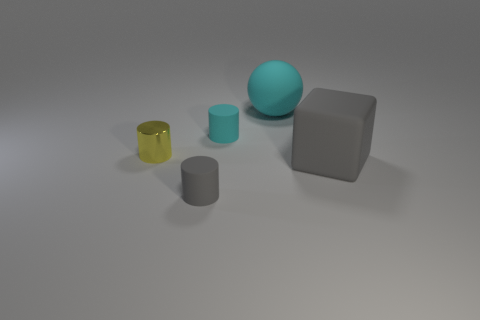


Model input question = <START> Is there any other thing that is the same size as the rubber cube <END> 
Prediction = yes
Ground Truth = yes


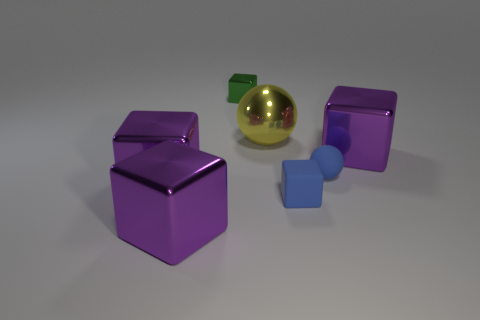


Model input question = <START> There is a small matte block that is on the left side of the large rubber thing that is left of the gray ball ; what is 
Prediction = brown
Ground Truth = brown


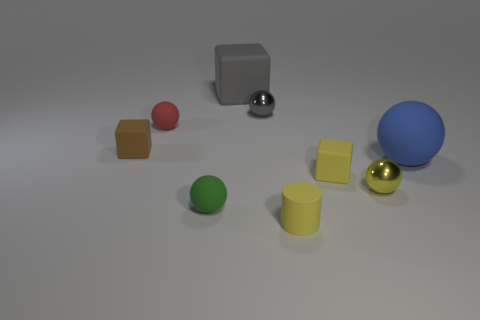


Model input question = <START> How many other objects are the same material as the blue object <END> 
Prediction = 2
Ground Truth = 2


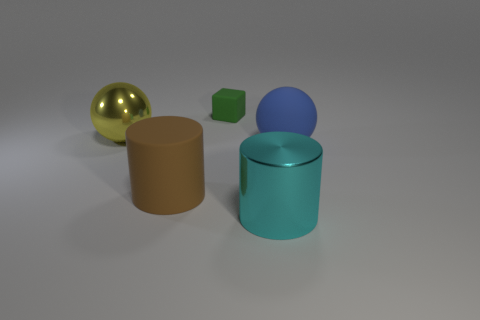


Model input question = <START> What is the shape of the brown thing to the right of the large brown metallic thing that is on the left side of the brown sphere 
Prediction = sphere
Ground Truth = sphere


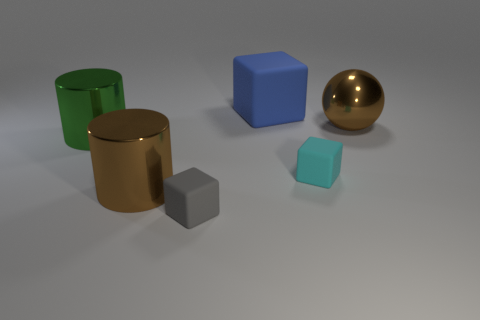


Model input question = <START> Are there more rubber objects behind the gray matte cube than cyan shiny blocks <END> 
Prediction = yes
Ground Truth = yes


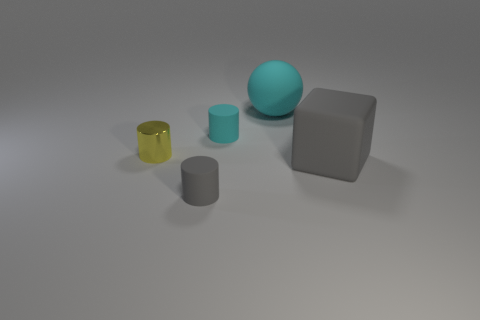


Model input question = <START> There is another tiny matte object that is the same shape as the tiny gray object ; what color is it <END> 
Prediction = cyan
Ground Truth = cyan


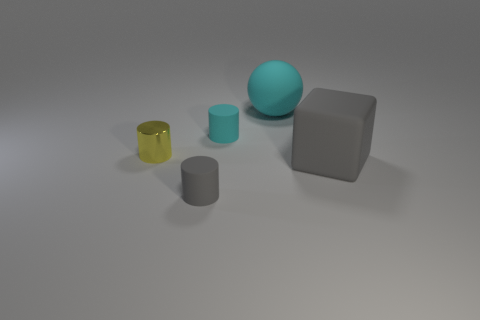


Model input question = <START> There is a yellow object ; is it the same size as the rubber object behind the yellow shiny thing <END> 
Prediction = no
Ground Truth = no


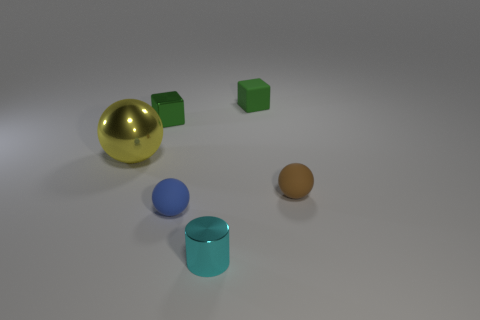


Model input question = <START> There is a small cube on the right side of the tiny blue thing that is behind the tiny cyan matte thing ; what is its color 
Prediction = purple
Ground Truth = purple


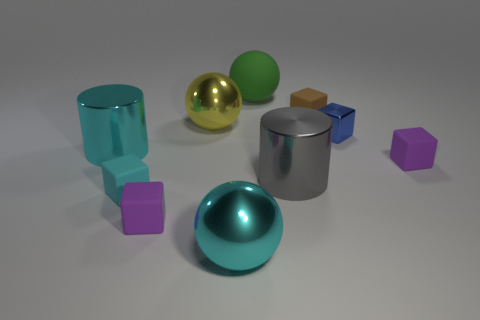


Model input question = <START> Is the number of cyan things in front of the purple matte cube greater than the number of metal cylinders left of the small metal sphere <END> 
Prediction = no
Ground Truth = no


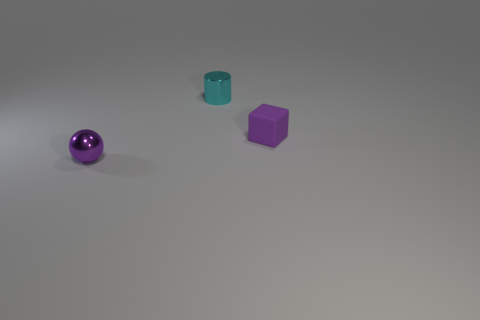


Model input question = <START> What shape is the large gray object that is made of the same material as the tiny red cube <END> 
Prediction = sphere
Ground Truth = sphere


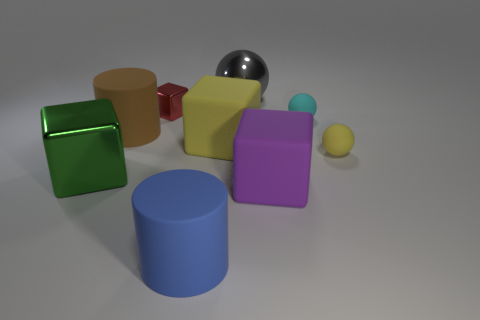


Model input question = <START> Are there any other things of the same color as the big rubber block <END> 
Prediction = no
Ground Truth = no


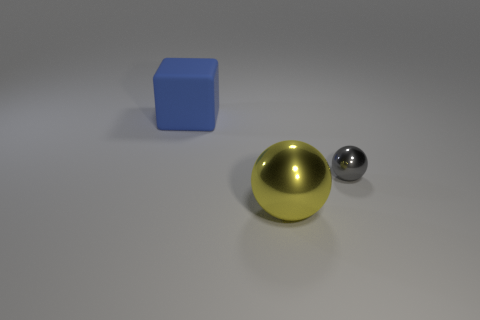


Model input question = <START> There is a rubber thing that is the same color as the cylinder ; what shape is it <END> 
Prediction = cube
Ground Truth = cube


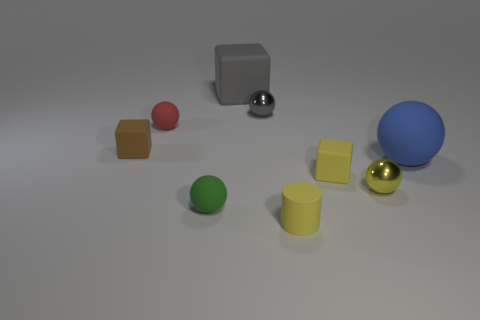


Model input question = <START> The small object to the left of the large matte object that is to the right of the big gray object is what shape <END> 
Prediction = cube
Ground Truth = cube


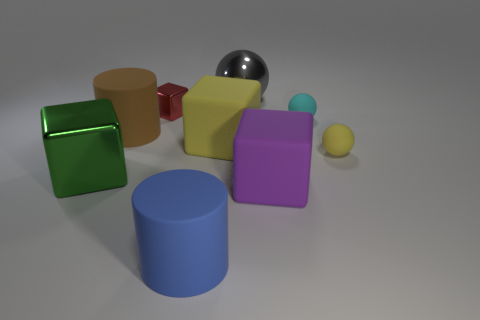


Model input question = <START> What material is the tiny cube that is to the right of the blue thing <END> 
Prediction = rubber
Ground Truth = rubber


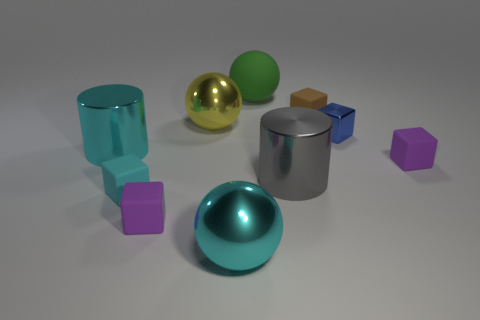

In [ ]:
# Display Results
from IPython.display import display, Image
import random

output_file = open('curr_valid_predictions.txt', 'r').readlines()
random.shuffle(output_file)
total_prints = 15
for line in output_file:
  if total_prints > 0:
    curr_line = line.split(" ")
    print("Model input question = " + " ".join(curr_line[3:]).strip("\n"))
    print("Prediction = " + curr_line[0])
    print("Ground Truth = " + curr_line[1])
    display(Image(f'../../data/CLEVR_v1.0/images/train/CLEVR_train_{curr_line[2]}.png'))
    print("")
    total_prints -= 1